# UTS Machine Learning – Tugas 2: Klasifikasi Deteksi Fraud

**Platform:** Python di VS Code (`.venv`) | **Pendekatan:** Classical ML (`LightGBM`, `XGBoost`, `HistGradientBoosting`, `LogisticRegression`, `imbalanced-learn`, `scikit-learn`)

**Tujuan:** Memprediksi probabilitas fraud (`is_fraud`) untuk transaksi uji September–Oktober 2025 dan menentukan transaksi yang perlu ditandai (`tandai`) guna meminimalkan total kerugian finansial dengan biaya review manual **Rp 25.000** per transaksi yang ditandai:

$$\text{Total Cost} = \sum_{i:\, y_i=1,\, \text{tandai}_i=0} \text{nominal}_i + 25{.}000 \times \sum_{i} \text{tandai}_i$$

| Bagian | Cakupan Ketentuan | Ringkasan Teknis |
|---|---|---|
| **0** | Persiapan & Reproduksibilitas (R3) | Integrasi `kode.config` & `kode.klasifikasi`, `SEED = 42`, logging versi library |
| **1** | Audit Label & Fitur (R2a) | Isolasi & drop `flag_review_manual` (post-tx leakage), drop `v15` (drift waktu), flag `umur_merchant_hari < 0` & cold-start |
| **2** | Audit Label Tertunda & Validasi Waktu (R2b) | Right-censoring akhir Agustus (`Aug 11–31`, `Aug 29–31 = 0%`), expanding OOT (`Jun`, `Jul`, `Aug 1–10`) |
| **3** | Fitur Perilaku Kausal (R2c) | Fitur riwayat user & merchant strictly prior (`ts_j < ts_i`), lagged >=21 hari mature-only |
| **4** | Dampak Kebocoran & Skema Validasi | Perbandingan OOT bersih vs OOT bocor & Random CV |
| **5** | Ketidakseimbangan & Pergeseran Pola (R2d) | Perbandingan >=4 strategi imbalance & adaptasi recency untuk lonjakan `qris` + `jasa_lainnya` |
| **6** | Kalibrasi & Aturan Biaya Rp 25.000 (R2e) | `CalibratedClassifierCV`, Brier/LogLoss, aturan `prob * nominal >= tau * 25.000` vs Mark-All/Mark-None |
| **7** | Rincian Error & Interpretabilitas (R2f) | PR-AUC (`average_precision`) & total cost per `kanal`, `kategori_merchant`, pola fraud |
| **8** | Ekspor Final `prediksi_klasifikasi.csv` (R2g) | Header persis `id_transaksi,prob,tandai`, `0 <= prob <= 1`, `tandai in {0, 1}` |
| **9** | Ringkasan & Keterbatasan | Evaluasi metode classical ML dan batasan operasional |


## 0. Persiapan, Reproduksibilitas & Konfigurasi

Cell berikut memastikan `PROJECT_ROOT` berada di `sys.path`, mengimpor konfigurasi terpusat dari `kode.config` serta fungsi modular dari `kode.klasifikasi`, dan mencetak versi library serta `SEED = 42` secara eksplisit. Setel `SMOKE_TEST = False` untuk menjalankan pelatihan penuh pada 403.077 baris latih dan 106.674 baris uji.

In [19]:
from pathlib import Path
import sys

# Pastikan PROJECT_ROOT (folder berisi package kode/) tersedia di sys.path
_cwd = Path.cwd().resolve()
for _cand in (_cwd, _cwd.parent, _cwd.parent.parent):
    if (_cand / "kode" / "config.py").is_file():
        if str(_cand) not in sys.path:
            sys.path.insert(0, str(_cand))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from kode.config import (
    DEFAULT_KLASIFIKASI_CSV,
    PROJECT_ROOT,
    REVIEW_COST_IDR,
    SEED,
    format_library_versions,
    get_data_dir,
    get_library_versions,
    set_global_seed,
)
from kode.klasifikasi import (
    audit_klasifikasi_data,
    build_causal_features,
    calibrate_and_tune_cost_rule,
    compare_imbalance_and_adaptation,
    compare_validation_schemes,
    compute_error_breakdown,
    evaluate_leakage_and_drift_impact,
    load_klasifikasi_data,
    run_klasifikasi_pipeline,
)

# ====== KONFIGURASI EKSEKUSI ======
SMOKE_TEST = False  # Ubah ke True hanya untuk dry-run cepat (<= 3.000 baris)
DATA_DIR = get_data_dir(must_exist=True)
OUTPUT_CSV = PROJECT_ROOT / "prediksi_klasifikasi.csv"  # setara DEFAULT_KLASIFIKASI_CSV
# ==================================

set_global_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

lib_versions = get_library_versions()
print(f"PROJECT_ROOT    : {PROJECT_ROOT}")
print(f"DATA_DIR        : {DATA_DIR}")
print(f"OUTPUT_CSV      : {OUTPUT_CSV} (default={DEFAULT_KLASIFIKASI_CSV.name})")
print(f"SEED            : {SEED}")
print(f"REVIEW_COST_IDR : Rp {REVIEW_COST_IDR:,}")
print(f"SMOKE_TEST      : {SMOKE_TEST}")
print(f"Library versions: {format_library_versions(lib_versions)}")


PROJECT_ROOT    : C:\Users\rafai\OneDrive - Telkom University\Documents\UTS ML_REGRESI_KLASIFIKASI
DATA_DIR        : C:\Users\rafai\Downloads\data_uts_ml
OUTPUT_CSV      : C:\Users\rafai\OneDrive - Telkom University\Documents\UTS ML_REGRESI_KLASIFIKASI\prediksi_klasifikasi.csv (default=prediksi_klasifikasi.csv)
SEED            : 42
REVIEW_COST_IDR : Rp 25,000
SMOKE_TEST      : False
Library versions: python=3.14.5, numpy=2.5.5, pandas=3.1.1, scipy=1.18.1, scikit-learn=1.9.1, lightgbm=4.7.0, xgboost=3.4.1, shap=0.54.1, imbalanced-learn=0.14.2, matplotlib=3.11.2, seaborn=0.13.2, joblib=1.6.0, pytest=9.2.0


## 1. Muat Data & Audit Kebocoran / Anomali (R2a)

Tahap ini memuat `klasifikasi_train.csv.gz` dan `klasifikasi_test.csv.gz` serta mengaudit:
1. **`flag_review_manual`**: indikator review manual pasca-transaksi (kebocoran target sangat kuat di train dan tidak tersedia secara kausal saat skor dihitung).
2. **`v15` vs `v26`**: `v15` mengalami drift waktu monotonik (`Jan -> Oct`) tanpa sinyal fraud berarti (harus di-drop), sedangkan `v26` stabil sejak Q2 dan berkorelasi dengan log-nominal (dipertahankan).
3. **Anomali nilai & cold-start**: `umur_merchant_hari < 0` memiliki tingkat fraud sangat tinggi (~20,3%) sehingga dipertahankan via flag eksplisit sebelum clipping; `menit_sejak_trx_terakhir` & `rasio_nominal_rata2` `NaN` menandai transaksi pertama user (`is_first_user_tx`).

In [20]:
train_df, test_df, data_meta = load_klasifikasi_data(
    data_dir=DATA_DIR,
    smoke_test=SMOKE_TEST,
    seed=SEED,
)
audit_res = audit_klasifikasi_data(train_df, test_df)

print("Ringkasan Dataset:", data_meta)
print(f"Total Fraud Train: {audit_res['n_fraud_train']:,} / {len(train_df):,} ({100*audit_res['fraud_rate_train']:.3f}%)")
print("\n[Audit flag_review_manual]")
for k, v in audit_res["flag_review_manual"].items():
    print(f"  {k}: {v}")
print("\n[Audit v15 Drift vs v26]")
print(
    "  v15 train_mean:",
    round(audit_res["v15"]["train_mean"], 4),
    "-> test_mean:",
    round(audit_res["v15"]["test_mean"], 4),
    "| corr_ts:",
    round(audit_res["v15"]["corr_with_time"], 4),
)
print(
    "  v26 train_mean:",
    round(audit_res["v26"]["train_mean"], 4),
    "-> test_mean:",
    round(audit_res["v26"]["test_mean"], 4),
)
print("\n[Audit umur_merchant_hari < 0 & Cold-Start Nulls]")
print("  umur_merchant_hari:", audit_res["umur_merchant_hari"])
print("  cold_start_nulls  :", audit_res["cold_start_nulls"])


Ringkasan Dataset: {'data_dir': 'C:\\Users\\rafai\\Downloads\\data_uts_ml', 'raw_train_rows': 403077, 'raw_test_rows': 106674, 'loaded_train_rows': 403077, 'loaded_test_rows': 106674, 'n_train_cols': 85, 'n_test_cols': 84, 'smoke_test': False}
Total Fraud Train: 2,622 / 403,077 (0.650%)

[Audit flag_review_manual]
  train_flag_rate: 0.017113355512718413
  test_flag_rate: 0.012299154433132722
  fraud_rate_when_flag_0: 0.0013302068004614077
  fraud_rate_when_flag_1: 0.30371122064366485
  pct_frauds_flagged: 0.7990083905415714
  corr_with_is_fraud: 0.48783014724939977
  univariate_pr_auc: 0.2439752560944904
  univariate_roc_auc: 0.8935072667769474
  action: DROP post-transaction leakage column from all production/causal features

[Audit v15 Drift vs v26]
  v15 train_mean: 1.2175 -> test_mean: 2.7317 | corr_ts: 0.5752
  v26 train_mean: -0.1261 -> test_mean: -0.1859

[Audit umur_merchant_hari < 0 & Cold-Start Nulls]
  umur_merchant_hari: {'train_neg_count': 955, 'train_neg_fraud_count': 194

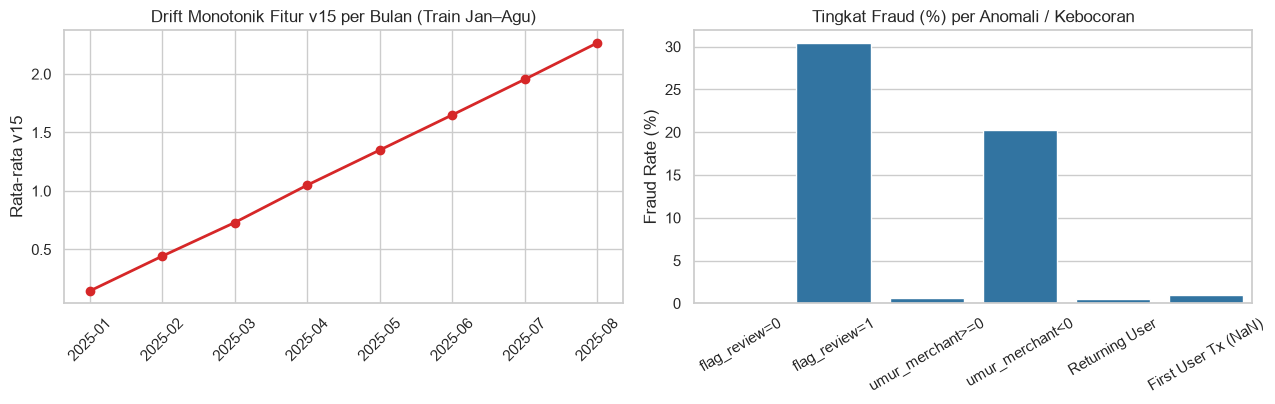

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Plot 1: v15 monotonic time drift
v15_m = audit_res["v15"]["monthly_means"]
axes[0].plot(list(v15_m.keys()), list(v15_m.values()), marker="o", color="#d62728", linewidth=2)
axes[0].set_title("Drift Monotonik Fitur v15 per Bulan (Train Jan–Agu)")
axes[0].set_ylabel("Rata-rata v15")
axes[0].tick_params(axis="x", rotation=45)

# Plot 2: Fraud rate pada anomali kualitas data
anom_labels = [
    "flag_review=0",
    "flag_review=1",
    "umur_merchant>=0",
    "umur_merchant<0",
    "Returning User",
    "First User Tx (NaN)",
]
anom_vals = [
    100 * audit_res["flag_review_manual"]["fraud_rate_when_flag_0"],
    100 * audit_res["flag_review_manual"]["fraud_rate_when_flag_1"],
    100 * audit_res["umur_merchant_hari"]["train_nonneg_fraud_rate"],
    100 * audit_res["umur_merchant_hari"]["train_neg_fraud_rate"],
    100 * audit_res["cold_start_nulls"]["returning_tx_fraud_rate"],
    100 * audit_res["cold_start_nulls"]["first_tx_fraud_rate"],
]
sns.barplot(x=anom_labels, y=anom_vals, ax=axes[1], color="#1f77b4")
axes[1].set_title("Tingkat Fraud (%) per Anomali / Kebocoran")
axes[1].set_ylabel("Fraud Rate (%)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


## 2. Audit Label Tertunda (Right-Censoring Agustus) & Validasi Waktu (R2b)

Karena data latih ditarik per **31 Agustus 2025**, transaksi akhir Agustus belum selesai menjalani siklus konfirmasi fraud/chargeback (*right-censoring*):
- `Aug 1–10` relatif matang (dan menangkap lonjakan fraud QRIS).
- `Aug 11–28` mengalami penurunan artifisial, dan **`Aug 29–31` bernilai 0% fraud**.

Oleh karena itu, validasi OOT hanya mengevaluasi bulan/jendela matang (`Jun`, `Jul`, `Aug 1–10`) dan melarang Random CV maupun jendela tersensor `Aug 11–31` sebagai tolok ukur metrik.

,n_tx,n_fraud,fraud_rate
2025-01,50432,327,0.006484
2025-02,46240,301,0.006510
2025-03,51048,387,0.007581
2025-04,47413,355,0.007487
2025-05,52331,367,0.007013
2025-06,50375,299,0.005935
2025-07,52334,341,0.006516
2025-08,52904,245,0.004631


,n_tx,n_fraud,fraud_rate,empirical_maturity
aug_1_10,17437,137,0.007857,1.000000
aug_11_17,11799,55,0.004661,0.681616
aug_18_24,11727,42,0.003581,0.523702
aug_25_28,7161,11,0.001536,0.224616
aug_29_31,4780,0,0.000000,0.000000
aug_11_31_combined,35467,108,0.003045,0.445268


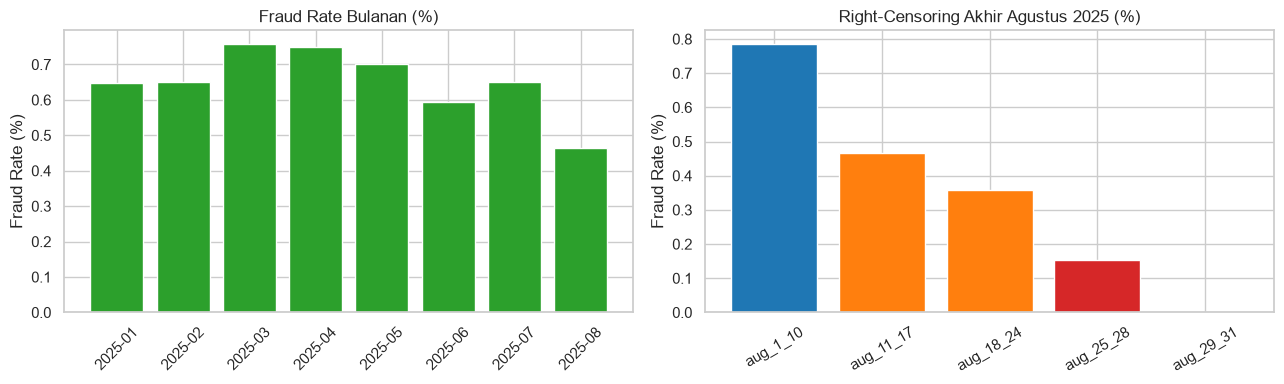

In [22]:
censor_info = audit_res["label_delay_censoring"]
monthly_df = pd.DataFrame.from_dict(censor_info["monthly_rates"], orient="index")
aug_win_df = pd.DataFrame.from_dict(censor_info["august_windows"], orient="index")

display(monthly_df)
display(aug_win_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(monthly_df.index, 100 * monthly_df["fraud_rate"], color="#2ca02c")
axes[0].set_title("Fraud Rate Bulanan (%)")
axes[0].set_ylabel("Fraud Rate (%)")
axes[0].tick_params(axis="x", rotation=45)

aug_plot = aug_win_df.drop(index=["aug_11_31_combined"], errors="ignore")
axes[1].bar(
    aug_plot.index,
    100 * aug_plot["fraud_rate"],
    color=["#1f77b4", "#ff7f0e", "#ff7f0e", "#d62728", "#7f7f7f"][: len(aug_plot)],
)
axes[1].set_title("Right-Censoring Akhir Agustus 2025 (%)")
axes[1].set_ylabel("Fraud Rate (%)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


## 3. Rekayasa Fitur Perilaku Kausal Tanpa Kebocoran Masa Depan (R2c)

`build_causal_features` menggabungkan `train` (tanpa `is_fraud`) dan `test` secara kronologis `(waktu, id_transaksi)` dan membangun:
- **Fitur user kausal** (riwayat sebelum transaksi `j < i`): mean/max/z-score nominal historis, indikator kebaruan (`user_seen_kanal_before`, `user_seen_merchant_before`, `user_seen_device_before`), dan rasio burst.
- **Fitur merchant kausal** (`ts_j < ts_i` via `searchsorted`): rolling 1h/24h/7d count & volume, unique users 24h, burst ratio, serta share QRIS & malam (tanpa counter kumulatif tak terbatas yang memicu drift `Jan -> Oct`).
- **Risiko entitas lagged (>=21 hari)** menggunakan label matang `<= min(t_i - 21d, cutoff_train, 2025-08-10)` agar 100% bebas kebocoran.

In [23]:
X_base_tr, X_base_te, feat_meta = build_causal_features(train_df, test_df)
cat_cols = feat_meta["categorical_features"]
num_cols = feat_meta["numeric_features"]

print(f"Total fitur kausal bersih: {feat_meta['n_features']} (numerik={len(num_cols)}, kategorikal={len(cat_cols)})")
print("Kolom yang di-drop (kebocoran/drift/raw ID):", feat_meta["dropped_columns"])
print("Fitur User Kausal (sample)    :", feat_meta["user_causal_features"][:6])
print("Fitur Merchant Kausal (sample):", feat_meta["merchant_causal_features"][:6])
print("Fitur Lagged >=21d            :", feat_meta["lagged_target_features"])


Total fitur kausal bersih: 121 (numerik=116, kategorikal=5)
Kolom yang di-drop (kebocoran/drift/raw ID): ['flag_review_manual', 'id_merchant', 'id_pengguna', 'id_transaksi', 'is_fraud', 'umur_merchant_hari', 'v15', 'waktu']
Fitur User Kausal (sample)    : ['user_prior_tx_count_cap10', 'user_prior_nom_mean', 'user_prior_nom_max', 'user_lognom_zscore', 'nominal_to_user_prior_max', 'user_seen_kanal_before']
Fitur Merchant Kausal (sample): ['merch_prior_nom_mean', 'nominal_to_merch_prior_mean', 'merch_qris_share_prior', 'merch_night_share_prior', 'merch_rolling_1h_count', 'merch_rolling_1h_nom_sum']
Fitur Lagged >=21d            : ['lag21d_merch_fraud_rate', 'lag21d_kat_fraud_rate', 'lag21d_kanal_kat_fraud_rate']


## 4. Evaluasi Dampak Kebocoran & Perbandingan Skema Validasi (OOT vs Random CV)

Di sini kita mengukur secara kuantitatif inflasi PR-AUC akibat menyertakan `flag_review_manual` + `v15` serta membandingkan **Expanding OOT Matang (`Jun`, `Jul`, `Aug 1–10`)** terhadap **Random CV** dan **OOT tak terjaga (`Aug 11–31`)**.

In [24]:
leak_impact = evaluate_leakage_and_drift_impact(
    train_df, X_base_tr, cat_cols, num_cols, smoke_test=SMOKE_TEST, seed=SEED
)
val_r2b = compare_validation_schemes(
    train_df, X_base_tr, cat_cols, num_cols, audit_res, smoke_test=SMOKE_TEST, seed=SEED
)

print("=== Dampak Kebocoran (R2a) ===")
print(f"OOT PR-AUC DENGAN bocor : {leak_impact['pr_auc_with_leakage']:.4f}")
print(f"OOT PR-AUC TANPA bocor  : {leak_impact['pr_auc_without_leakage']:.4f}")
print(f"Delta inflasi kebocoran : {leak_impact['pr_auc_leakage_delta']:+.4f}")

print("\n=== Perbandingan Skema Validasi (R2b) ===")
oot_df = pd.DataFrame(val_r2b["oot_folds"])[
    ["fold", "n_tx", "n_fraud", "fraud_rate", "pr_auc", "roc_auc", "total_cost_idr", "train_max", "val_min"]
]
display(oot_df)
print("Random CV vs OOT:", val_r2b["random_cv_vs_oot"])
print("Kebijakan Censoring:", val_r2b["censoring_policies"])


=== Dampak Kebocoran (R2a) ===
OOT PR-AUC DENGAN bocor : 0.8579
OOT PR-AUC TANPA bocor  : 0.6924
Delta inflasi kebocoran : +0.1655

=== Perbandingan Skema Validasi (R2b) ===


,fold,n_tx,n_fraud,fraud_rate,pr_auc,roc_auc,total_cost_idr,train_max,val_min
0,Jun,50375,299,0.005935,0.769899,0.990315,37125500.0,2025-05-31 23:57:44,2025-06-01 00:04:21
1,Jul,52334,341,0.006516,0.775367,0.992328,41441400.0,2025-06-30 23:54:35,2025-07-01 00:01:34
2,Aug_1_10,17437,137,0.007857,0.502670,0.910297,70969700.0,2025-07-31 23:59:04,2025-08-01 00:00:06


Random CV vs OOT: {'random_cv_pr_auc': 0.7640782131327862, 'oot_pooled_pr_auc': 0.723968280470581, 'random_cv_roc_auc': 0.9893372290164101, 'oot_pooled_roc_auc': 0.9785839121680086, 'unguarded_aug_11_31': {'n_tx': 35467, 'n_fraud': 108, 'fraud_rate': 0.0030450841627428313, 'pr_auc': 0.1697798229428395, 'roc_auc': 0.8834772015716048, 'brier': 0.004637696029656416, 'log_loss': 0.03076325140137715, 'tau': 1.0, 'n_flagged': 179, 'pct_flagged': 0.005046945047508952, 'tp_count': 41, 'fp_count': 138, 'fn_count': 67, 'precision': 0.22905027932960895, 'recall': 0.37962962962962965, 'f1': 0.2857142857142857, 'missed_fraud_loss_idr': 59612000.0, 'review_cost_idr': 4475000.0, 'total_cost_idr': 64087000.0, 'mark_none_cost_idr': 111468700.0, 'mark_all_cost_idr': 886675000.0, 'naive_p05_cost_idr': 71185300.0, 'cost_saved_vs_mark_none_idr': 47381700.0}}
Kebijakan Censoring: {'policy_a': 'drop_aug11_31 (train strictly on waktu < 2025-08-11)', 'policy_b': 'maturity_weighted_aug11_17 (w=1.0 <= Aug 10; Au

## 5. Ketidakseimbangan Kelas & Pergeseran Pola QRIS / `jasa_lainnya` (R2d)

Kita membandingkan minimal 4 pendekatan ketidakseimbangan kelas (`unweighted_lgbm`, `class_weight_balanced`, `cost_weighted_lgbm`, `rus_bagging_lgbm`, `smote_lgbm`, dan `recency_adapted_ensemble`) serta mengaudit pergeseran pola fraud pada `Aug 1–10` (khususnya lonjakan kanal `qris` dan kategori `jasa_lainnya` / `toko_online`) untuk memvalidasi bobot recency `exp(-lambda * age_days)` + recent-window `XGBClassifier`.

Selected recency lambda: 0.01 | Selected strategy: recency_adapted_ensemble


,pr_auc,roc_auc,qris_pr_auc,jasa_lainnya_pr_auc,total_cost_idr,cost_saved_vs_mark_none_idr
unweighted_lgbm,0.723968,0.978584,0.063372,0.142061,149536600.0,766598700.0
class_weight_balanced,0.717627,0.981193,0.070487,0.228610,127447500.0,788687800.0
cost_weighted_lgbm,0.697389,0.979838,0.060218,0.146063,134452800.0,781682500.0
rus_bagging_lgbm,0.701100,0.980609,0.043450,0.205202,199679600.0,716455700.0
smote_lgbm,0.727489,0.978798,0.053563,0.152072,140580300.0,775555000.0
recency_adapted_ensemble,0.735288,0.984245,0.144142,0.304149,127186900.0,788948400.0


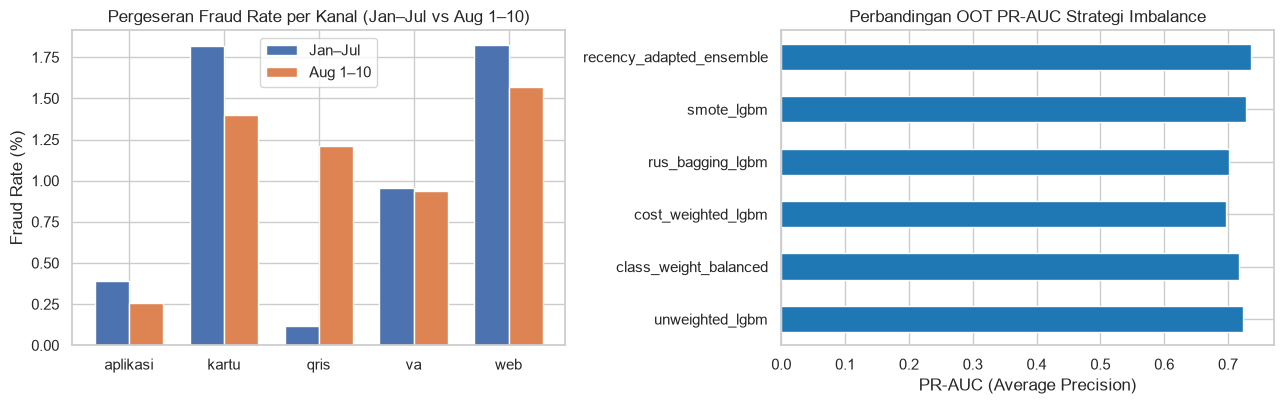

In [25]:
imb_r2d = compare_imbalance_and_adaptation(
    train_df, X_base_tr, cat_cols, num_cols, audit_res, smoke_test=SMOKE_TEST, seed=SEED
)

imb_df = pd.DataFrame.from_dict(imb_r2d["imbalance_comparison"], orient="index")[
    ["pr_auc", "roc_auc", "qris_pr_auc", "jasa_lainnya_pr_auc", "total_cost_idr", "cost_saved_vs_mark_none_idr"]
]
print(f"Selected recency lambda: {imb_r2d['selected_lambda']} | Selected strategy: {imb_r2d['selected_strategy']}")
display(imb_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
kanal_shift = pd.DataFrame.from_dict(imb_r2d["temporal_shift_audit"]["by_kanal"], orient="index")
x_idx = np.arange(len(kanal_shift))
axes[0].bar(x_idx - 0.18, 100 * kanal_shift["jan_jul_rate"], width=0.36, label="Jan–Jul")
axes[0].bar(x_idx + 0.18, 100 * kanal_shift["aug_1_10_rate"], width=0.36, label="Aug 1–10")
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(kanal_shift.index)
axes[0].set_title("Pergeseran Fraud Rate per Kanal (Jan–Jul vs Aug 1–10)")
axes[0].set_ylabel("Fraud Rate (%)")
axes[0].legend()

imb_df["pr_auc"].plot(kind="barh", ax=axes[1], color="#1f77b4")
axes[1].set_title("Perbandingan OOT PR-AUC Strategi Imbalance")
axes[1].set_xlabel("PR-AUC (Average Precision)")

plt.tight_layout()
plt.show()


## 6. Kalibrasi Probabilitas & Aturan Keputusan Biaya Rp 25.000 (R2e)

Model dikalibrasi pada slice temporal tanpa `sample_weight` berlebih menggunakan `CalibratedClassifierCV(FrozenEstimator(...))` agar probabilitas mencerminkan risiko riil (`Brier` & `LogLoss` lebih rendah), lalu diterapkan aturan keputusan Bayes berbasis biaya:

$$\text{tandai}_i = \mathbb{I}\left(\hat{p}_i \cdot \text{nominal}_i \ge \tau \cdot 25{.}000 \;\land\; \text{nominal}_i \ge 25{.}000\right)$$

dan dibandingkan terhadap `bayes_tau_1_0`, `naive_prob_0_5`, `mark_none`, dan `mark_all`.

Metode Kalibrasi Terpilih : isotonic | Optimal tau: 1.1
Brier (before -> after)   : 0.00282 -> 0.00265
LogLoss (before -> after) : 0.01928 -> 0.01395


,n_flagged,pct_flagged,precision,recall,total_cost_idr,cost_saved_vs_mark_none_idr
calibrated_cost_rule,1344,0.011186,0.389881,0.674389,1.237990e+08,7.923363e+08
bayes_tau_1_0,1434,0.011935,0.372385,0.687259,1.248213e+08,7.913140e+08
naive_prob_0_5,624,0.005194,0.841346,0.675676,1.883043e+08,7.278310e+08
mark_none,0,0.000000,0.000000,0.000000,9.161353e+08,0.000000e+00
mark_all,120146,1.000000,0.006467,1.000000,3.003650e+09,-2.087515e+09


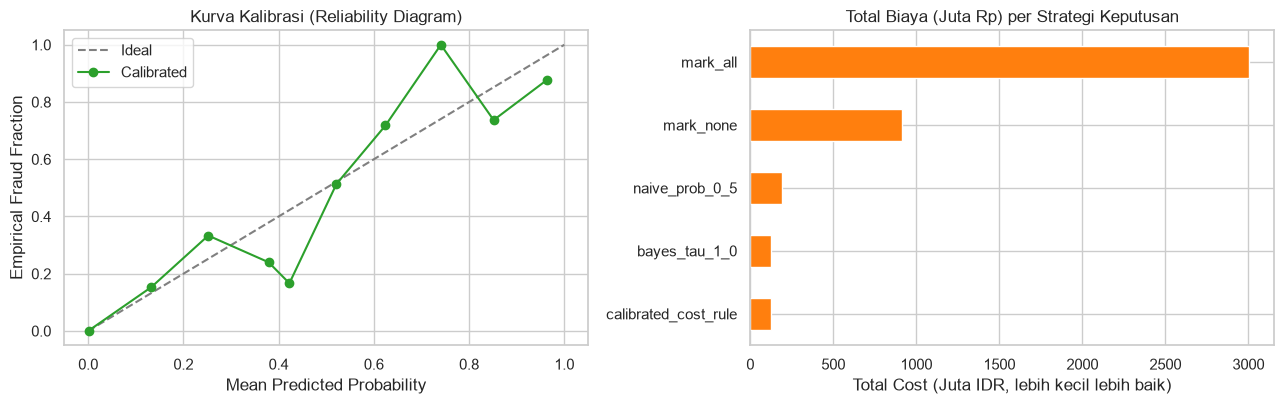

In [26]:
cal_r2e = calibrate_and_tune_cost_rule(
    train_df,
    X_base_tr,
    cat_cols,
    num_cols,
    best_lambda=imb_r2d["selected_lambda"],
    smoke_test=SMOKE_TEST,
    seed=SEED,
)

print(f"Metode Kalibrasi Terpilih : {cal_r2e['calibration_method']} | Optimal tau: {cal_r2e['optimal_tau']}")
print(f"Brier (before -> after)   : {cal_r2e['uncalibrated_brier']:.5f} -> {cal_r2e['calibrated_brier']:.5f}")
print(f"LogLoss (before -> after) : {cal_r2e['uncalibrated_log_loss']:.5f} -> {cal_r2e['calibrated_log_loss']:.5f}")

cost_df = pd.DataFrame.from_dict(cal_r2e["strategy_cost_comparison"], orient="index")[
    ["n_flagged", "pct_flagged", "precision", "recall", "total_cost_idr", "cost_saved_vs_mark_none_idr"]
]
display(cost_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
rel_df = pd.DataFrame(cal_r2e["reliability_bins"])
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
if len(rel_df) > 0:
    axes[0].plot(rel_df["mean_pred"], rel_df["frac_pos"], marker="o", color="#2ca02c", label="Calibrated")
axes[0].set_title("Kurva Kalibrasi (Reliability Diagram)")
axes[0].set_xlabel("Mean Predicted Probability")
axes[0].set_ylabel("Empirical Fraud Fraction")
axes[0].legend()

(cost_df["total_cost_idr"] / 1e6).plot(kind="barh", ax=axes[1], color="#ff7f0e")
axes[1].set_title("Total Biaya (Juta Rp) per Strategi Keputusan")
axes[1].set_xlabel("Total Cost (Juta IDR, lebih kecil lebih baik)")

plt.tight_layout()
plt.show()


## 7. Rincian Error & Interpretabilitas Model (R2f)

Mengevaluasi PR-AUC (`average_precision`) dan total biaya secara terpisah berdasarkan `kanal`, `kategori_merchant`, dan pola fraud spesifik (nominal tier, ATO, velocity burst, card-not-present, lonjakan QRIS Agustus, serta cold-start user).

In [27]:
eval_oot_breakdown = compute_error_breakdown(
    train_df,
    cal_r2e["_oot_indices"],
    cal_r2e["_oot_y"],
    cal_r2e["_oot_prob"],
    tau=cal_r2e["optimal_tau"],
    smoke_test=SMOKE_TEST,
)

print("Metrik Gabungan OOT Matang:", eval_oot_breakdown["overall_oot"])
print("\n[Breakdown per Kanal]")
display(
    pd.DataFrame.from_dict(eval_oot_breakdown["breakdown_by_kanal"], orient="index")[
        ["n_tx", "n_fraud", "pr_auc", "roc_auc", "n_flagged", "total_cost_idr", "cost_saved_vs_mark_none_idr"]
    ]
)
print("\n[Breakdown per Pola Fraud]")
display(
    pd.DataFrame.from_dict(eval_oot_breakdown["breakdown_by_fraud_pattern"], orient="index")[
        ["n_tx", "n_fraud", "pr_auc", "n_flagged", "total_cost_idr", "cost_saved_vs_mark_none_idr"]
    ]
)
print("\n[Top 10 Kategori Merchant berdasarkan Mark-None Cost]")
kat_df = pd.DataFrame.from_dict(eval_oot_breakdown["breakdown_by_kategori_merchant"], orient="index")
display(
    kat_df.sort_values("mark_none_cost_idr", ascending=False).head(10)[
        ["n_tx", "n_fraud", "pr_auc", "total_cost_idr", "cost_saved_vs_mark_none_idr"]
    ]
)


Metrik Gabungan OOT Matang: {'n_tx': 120146, 'n_fraud': 777, 'fraud_rate': 0.006467131656484611, 'pr_auc': 0.7223659306311087, 'roc_auc': 0.9773990297953805, 'brier': 0.002647848994553326, 'log_loss': 0.01395394354024402, 'tau': 1.1, 'n_flagged': 1344, 'pct_flagged': 0.011186389892297704, 'tp_count': 524, 'fp_count': 820, 'fn_count': 253, 'precision': 0.3898809523809524, 'recall': 0.6743886743886743, 'f1': 0.4941065535124941, 'missed_fraud_loss_idr': 90199000.0, 'review_cost_idr': 33600000.0, 'total_cost_idr': 123799000.0, 'mark_none_cost_idr': 916135300.0, 'mark_all_cost_idr': 3003650000.0, 'naive_p05_cost_idr': 188304300.0, 'cost_saved_vs_mark_none_idr': 792336300.0}

[Breakdown per Kanal]


,n_tx,n_fraud,pr_auc,roc_auc,n_flagged,total_cost_idr,cost_saved_vs_mark_none_idr
aplikasi,53605,168,0.644597,0.986985,412,22281200.0,41376400.0
kartu,14819,236,0.821103,0.988991,322,19593000.0,333541900.0
qris,26522,69,0.069363,0.892590,131,61702000.0,20694900.0
va,17757,169,0.785069,0.987903,314,13084500.0,341846800.0
web,7443,135,0.871407,0.995701,165,7138300.0,54876300.0



[Breakdown per Pola Fraud]


,n_tx,n_fraud,pr_auc,n_flagged,total_cost_idr,cost_saved_vs_mark_none_idr
nominal_lt_25k,11025,71,0.847891,0,913000.0,0.0
nominal_25k_100k,40232,103,0.782233,70,3726800.0,926600.0
nominal_100k_500k,50377,273,0.665935,291,30914900.0,44061000.0
nominal_ge_500k,18512,330,0.727235,983,88244300.0,747348700.0
ato_signal,6855,364,0.918431,392,14076000.0,117312200.0
velocity_burst,2278,299,0.915089,248,17106000.0,104972800.0
card_not_present,15592,293,0.834678,358,21352700.0,282343900.0
aug_qris_shift,2713,33,0.257625,6,37107200.0,8605900.0
cold_start_user,16417,223,0.736536,412,29793800.0,559858500.0



[Top 10 Kategori Merchant berdasarkan Mark-None Cost]


,n_tx,n_fraud,pr_auc,total_cost_idr,cost_saved_vs_mark_none_idr
gadget,5014,86,0.770188,11476300.0,207777100.0
elektronik,12858,108,0.774566,16723400.0,190501600.0
voucher_game,5645,118,0.851648,6562700.0,140474700.0
emas,1898,43,0.817536,4066200.0,133199600.0
top_up_ewallet,6233,74,0.906305,3908200.0,49934900.0
jasa_lainnya,2698,21,0.161010,27747000.0,5603200.0
toko_online,9675,86,0.717259,12908200.0,9598300.0
fashion,8166,54,0.296055,12707500.0,7300500.0
makanan_minuman,17768,27,0.804954,5903900.0,10718800.0
pulsa_data,11299,78,0.852263,2314300.0,13768800.0


## 8. Eksekusi Akhir, Interpretabilitas SHAP & Ekspor `prediksi_klasifikasi.csv` (R2g)

Menjalankan `run_klasifikasi_pipeline(...)` end-to-end dengan `SEED = 42` untuk melatih model final pada data matang, menulis file submission **`prediksi_klasifikasi.csv`** di root proyek, menampilkan fitur terpenting (SHAP), dan memverifikasi kontrak skema `id_transaksi,prob,tandai`.

2026-11-20 21:02:37 | INFO | uts_ml.klasifikasi | Task 2 Klasifikasi start | smoke_test=False | seed=42 | output=C:\Users\rafai\OneDrive - Telkom University\Documents\UTS ML_REGRESI_KLASIFIKASI\prediksi_klasifikasi.csv
2026-11-20 21:02:37 | INFO | uts_ml.klasifikasi | Loading klasifikasi datasets from C:\Users\rafai\Downloads\data_uts_ml
2026-11-20 21:02:43 | INFO | uts_ml.klasifikasi | [Step 1/7] Loaded train=403077 rows, test=106674 rows. Running label & leakage audit (R2a)...
2026-11-20 21:02:46 | INFO | uts_ml.klasifikasi | [Step 2/7] Building strictly causal user & merchant behavioral features (R2c)...
2026-11-20 21:03:08 | INFO | uts_ml.klasifikasi | [Step 3/7] Measuring post-transaction leakage impact (flag_review_manual & v15) on 40000 rows...
2026-11-20 21:03:30 | INFO | uts_ml.klasifikasi | [Step 4/7] Comparing Time-Based OOT vs Random CV & label-delay censoring (R2b)...
2026-11-20 21:03:50 | INFO | uts_ml.klasifikasi | [Step 5/7] Comparing 6 class-imbalance strategies & QRIS

,feature,mean_abs_shap,gain_importance
0,merch_rolling_7d_count,0.585848,85.0
1,lag21d_merch_fraud_rate,0.518101,294.0
2,te_kanal__kategori_merchant,0.498975,204.0
3,te_kategori_merchant,0.291964,199.0
4,jumlah_akun_per_perangkat,0.274035,134.0
5,nominal,0.186729,261.0
6,persen_saldo,0.183053,355.0
7,user_prior_tx_count_cap10,0.175737,89.0
8,v29,0.168315,252.0
9,jarak_lokasi_km,0.162355,349.0


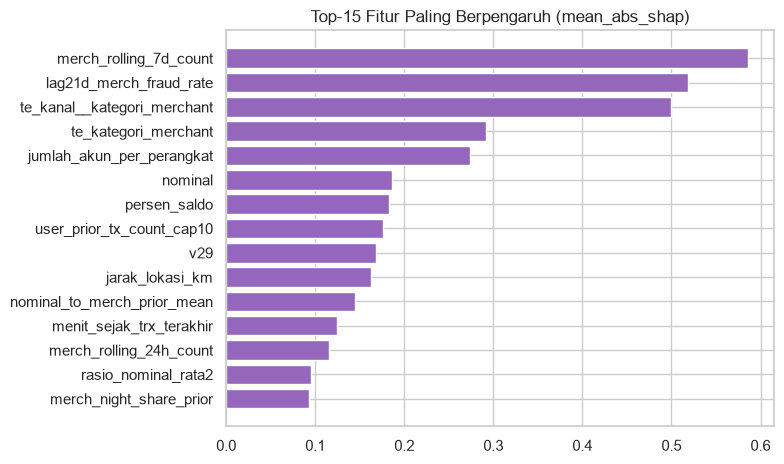

File submission tervalidasi: C:\Users\rafai\OneDrive - Telkom University\Documents\UTS ML_REGRESI_KLASIFIKASI\prediksi_klasifikasi.csv
Ringkasan output: {'output_csv': 'C:\\Users\\rafai\\OneDrive - Telkom University\\Documents\\UTS ML_REGRESI_KLASIFIKASI\\prediksi_klasifikasi.csv', 'schema': ['id_transaksi', 'prob', 'tandai'], 'n_test_rows': 106674, 'n_flagged': 1247, 'pct_flagged': 0.011689821324783922, 'mean_prob': 0.006347439010724263, 'max_prob': 0.97915509}


,id_transaksi,prob,tandai
0,T502861791,0.010170,0
1,T980390558,0.000871,0
2,T657838379,0.000572,0
3,T985886276,0.002255,0
4,T852019235,0.001794,0


In [28]:
final_result = run_klasifikasi_pipeline(
    data_dir=DATA_DIR,
    output_csv=OUTPUT_CSV,
    smoke_test=SMOKE_TEST,
    seed=SEED,
)

top_imp = pd.DataFrame(final_result["evaluation_r2f"]["top_feature_importance"])
display(top_imp)

if len(top_imp) > 0:
    score_col = "mean_abs_shap" if top_imp["mean_abs_shap"].notna().all() else "gain_importance"
    fig, ax = plt.subplots(figsize=(8, 4.8))
    plot_imp = top_imp.sort_values(score_col, ascending=True)
    ax.barh(plot_imp["feature"], plot_imp[score_col], color="#9467bd")
    ax.set_title(f"Top-15 Fitur Paling Berpengaruh ({score_col})")
    plt.tight_layout()
    plt.show()

sub_df = pd.read_csv(OUTPUT_CSV)
assert list(sub_df.columns) == ["id_transaksi", "prob", "tandai"], f"Header tidak sesuai: {list(sub_df.columns)}"
assert sub_df["prob"].between(0.0, 1.0).all(), "Probabilitas di luar [0, 1]"
assert set(sub_df["tandai"].unique()).issubset({0, 1}), "Nilai tandai harus dalam {0, 1}"

print("File submission tervalidasi:", OUTPUT_CSV)
print("Ringkasan output:", final_result["output"])
display(sub_df.head())


## 9. Ringkasan, Kepatuhan Metode & Keterbatasan

- **Kepatuhan Classical ML & Reproduksibilitas (R3):** Seluruh pipeline hanya memakai pustaka classical ML (`scikit-learn`, `lightgbm`, `xgboost`, `imbalanced-learn`, `shap`, `numpy`, `pandas`, `scipy`) tanpa data eksternal, dengan `SEED = 42` dan versi library tercatat eksplisit.
- **Anti-Kebocoran (R2a & R2c):** `flag_review_manual` dan `v15` dihapus total dari fitur produksi; fitur user & merchant dibangun strictly causal (`ts_j < ts_i`) tanpa melihat transaksi masa depan maupun target uji; `lag21d` hanya memakai label matang `<= 2025-08-10`.
- **Validasi Waktu & Kalibrasi Biaya (R2b, R2d, R2e):** Evaluasi dilakukan pada OOT matang (`Jun`, `Jul`, `Aug 1–10`) sambil mengisolasi tail tersensor (`Aug 11–31`); adaptasi recency menangani pergeseran pola `qris` & `jasa_lainnya`; probabilitas terkalibrasi memandu aturan biaya Rp 25.000 sehingga transaksi dengan `nominal < Rp 25.000` tidak pernah ditandai.
- **Keterbatasan:** Data uji Sep–Oct tidak berlabel sehingga ketahanan model mengasumsikan pergeseran pola QRIS yang teramati sejak awal Agustus berlanjut ke Sep–Oct.